# Eksperimen & Benchmark Linear Regression from Scratch

Notebook ini melatih model `linear_regression` (from scratch) menggunakan dataset `src/train.csv` (data rating pemain sepak bola) dan membandingkannya secara komprehensif dengan implementasi resmi Scikit-Learn:
- **Scratch (OLS / Ridge / Lasso)**
- **Scikit-Learn LinearRegression (OLS)**
- **Scikit-Learn Ridge (L2)**
- **Scikit-Learn Lasso (L1)**

Evaluasi dilakukan dengan:
1. **Tabel Metrik**: MAE, MSE, RMSE, dan R²
2. **Visualisasi**: Predicted vs Actual Plot & Residual Plot (Analisis Residual)

In [ ]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import class Linear Regression buatan sendiri
from linear_regression import linear_regression

# Scikit-Learn imports
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression as SklearnLinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
print("Semua modul berhasil di-import!")

Semua modul berhasil di-import!


## 1. Load Data

In [17]:
df = pd.read_csv('train.csv')
print(f"Ukuran dataset: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Ukuran dataset: 12883 baris, 50 kolom


,id,potensi,nilai_pasar,gaji,usia,tinggi_cm,berat_kg,level_liga,kaki_lemah,gerakan_skill,reputasi_internasional,klausul_pelepasan,umpan_silang,penyelesaian,akurasi_sundulan,umpan_pendek,tendangan_voli,skill_dribel,lengkung_bola,akurasi_tendangan_bebas,umpan_panjang,kontrol_bola,akselerasi,kecepatan_sprint,kelincahan,reaksi,keseimbangan,kekuatan_tembakan,lompatan,stamina,kekuatan,tembakan_jarak_jauh,agresivitas,intersepsi,posisi_mental,visi,penalti,ketenangan,kesadaran_menjaga,tekel_berdiri,tekel_meluncur,kiper_menyelam,kiper_menangkap,kiper_menendang,kiper_posisi,kiper_refleks,posisi_utama,kaki_dominan,tipe_badan,target
0,0dd490b1,61,NaN,505,35,191.0,87.0,1.000000,1,1,1,6.200308e+04,12,18,14,21,17,18,17,12,27,18,31.0,30,26,61,33,46,46,38,48,16,32,16,10,55,13,38,14,11,15,59,62,62,62.0,63.0,Kiper,Kanan,Normal (185+),62
1,efa2a538,74,NaN,24799,27,181.0,74.0,1.014541,2,2,1,8.123519e+06,65,76,67,71,72,70,64,57,64,72,73.0,75,74,75,74,74,76,73,67,71,36,45,77,73,72,76,22,26,24,6,5,12,7.0,10.0,Penyerang Tengah,Kanan,Normal (170-185),73
2,5db63d65,81,2116922.0,1972,21,174.0,64.0,1.000000,4,2,1,3.946505e+06,64,62,52,61,50,69,64,41,57,65,82.0,75,83,59,85,68,70,73,60,64,57,30,60,59,53,58,30,30,30,13,14,10,5.0,14.0,Penyerang Sayap Kiri,Kanan,Kurus (170-185),66
3,27608e7a,65,NaN,988,31,188.0,75.0,3.009559,3,1,1,9.105786e+05,61,46,60,58,39,55,46,35,56,59,73.0,71,66,60,64,54,86,78,74,44,71,60,53,52,52,58,59,63,60,14,12,7,13.0,12.0,Bek Kanan,Kanan,Normal (185+),65
4,104a5aaf,83,18791753.0,23833,24,173.0,65.0,1.016170,4,4,2,3.615582e+07,75,45,60,75,40,73,70,33,68,74,78.0,78,74,74,81,69,77,81,75,52,78,76,69,64,46,71,77,79,75,13,13,4,6.0,15.0,Bek Kiri,Kiri,Normal (170-185),78


## 2. Preprocessing & Feature Standardization

Tahapan:
1. Drop kolom `id`
2. Imputasi missing values: median (numerik) dan modus (kategorikal)
3. One-Hot Encoding fitur kategorikal
4. Split 80% Train, 20% Test
5. **Standarisasi Fitur Numerik**: Menghitung mean $\mu$ dan std $\sigma$ pada training set, lalu menggunakannya untuk menstandarkan test set (mencegah data leakage).

In [18]:
# Pisahkan Target dan Fitur
X = df.drop(columns=['id', 'target'])
y = df['target'].values

# Identifikasi kolom numerik dan kategorikal
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

# Imputasi missing values
for col in numeric_cols:
    if X[col].isnull().sum() > 0:
        X[col] = X[col].fillna(X[col].median())

for col in cat_cols:
    if X[col].isnull().sum() > 0:
        X[col] = X[col].fillna(X[col].mode()[0])

# One-Hot Encoding
X = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=float)

# Train - Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X.values, y, test_size=0.2, random_state=42
)

# Standarisasi Fitur (Z-Score Normalization)
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)
std[std == 0] = 1.0  # hindari divisi dengan 0

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

print(f"Data siap!")
print(f"X_train shape: {X_train_scaled.shape}")
print(f"X_test shape:  {X_test_scaled.shape}")

Data siap!
X_train shape: (10306, 66)
X_test shape:  (2577, 66)


## 3. Training: Model Scratch vs Scikit-Learn Models

Kita melatih 4 model sekaligus:
1. **Linear Regression (Scratch)** - Menggunakan L2 regularization (`penalty='l2'`, `lmbda=0.01`)
2. **Linear Regression (Scikit-Learn OLS)**
3. **Ridge Regression (Scikit-Learn L2)**
4. **Lasso Regression (Scikit-Learn L1)**

In [19]:
# 1. Model Scratch
model_scratch = linear_regression(penalty='l2', lmbda=0.01)
model_scratch.fit(X_train_scaled, y_train)

# 2. Scikit-Learn Linear Regression (OLS)
model_sklearn_lr = SklearnLinearRegression()
model_sklearn_lr.fit(X_train_scaled, y_train)

# 3. Scikit-Learn Ridge (L2)
model_sklearn_ridge = Ridge(alpha=0.01)
model_sklearn_ridge.fit(X_train_scaled, y_train)

# 4. Scikit-Learn Lasso (L1)
model_sklearn_lasso = Lasso(alpha=0.01, max_iter=10000)
model_sklearn_lasso.fit(X_train_scaled, y_train)

print("Semua model berhasil dilatih!")

Semua model berhasil dilatih!


## 4. Evaluasi Metrik Regresi (MAE, MSE, RMSE, R²)

In [20]:
# Kumpulkan semua prediksi
predictions = {
    'Scratch (L2)': model_scratch.predict(X_test_scaled),
    'Sklearn LinearRegression': model_sklearn_lr.predict(X_test_scaled),
    'Sklearn Ridge': model_sklearn_ridge.predict(X_test_scaled),
    'Sklearn Lasso': model_sklearn_lasso.predict(X_test_scaled)
}

# Hitung metrik untuk setiap model
metrics_list = []
for name, y_pred in predictions.items():
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    metrics_list.append({
        'Model': name,
        'MAE': round(mae, 4),
        'MSE': round(mse, 4),
        'RMSE': round(rmse, 4),
        'R² Score': round(r2, 4)
    })

df_metrics = pd.DataFrame(metrics_list)
df_metrics

,Model,MAE,MSE,RMSE,R² Score
0,Scratch (L2),1.3339,2.9181,1.7082,0.9402
1,Sklearn LinearRegression,1.3221,2.8780,1.6965,0.9410
2,Sklearn Ridge,1.3221,2.8780,1.6965,0.9410
3,Sklearn Lasso,1.3327,2.9147,1.7073,0.9403


## 5. Visualisasi 1: Predicted vs Actual Plot

Garis putus-putus merah merepresentasikan prediksi ideal $y = \hat{y}$. Semakin rapat titik-titik di sekitar garis merah, semakin akurat model.

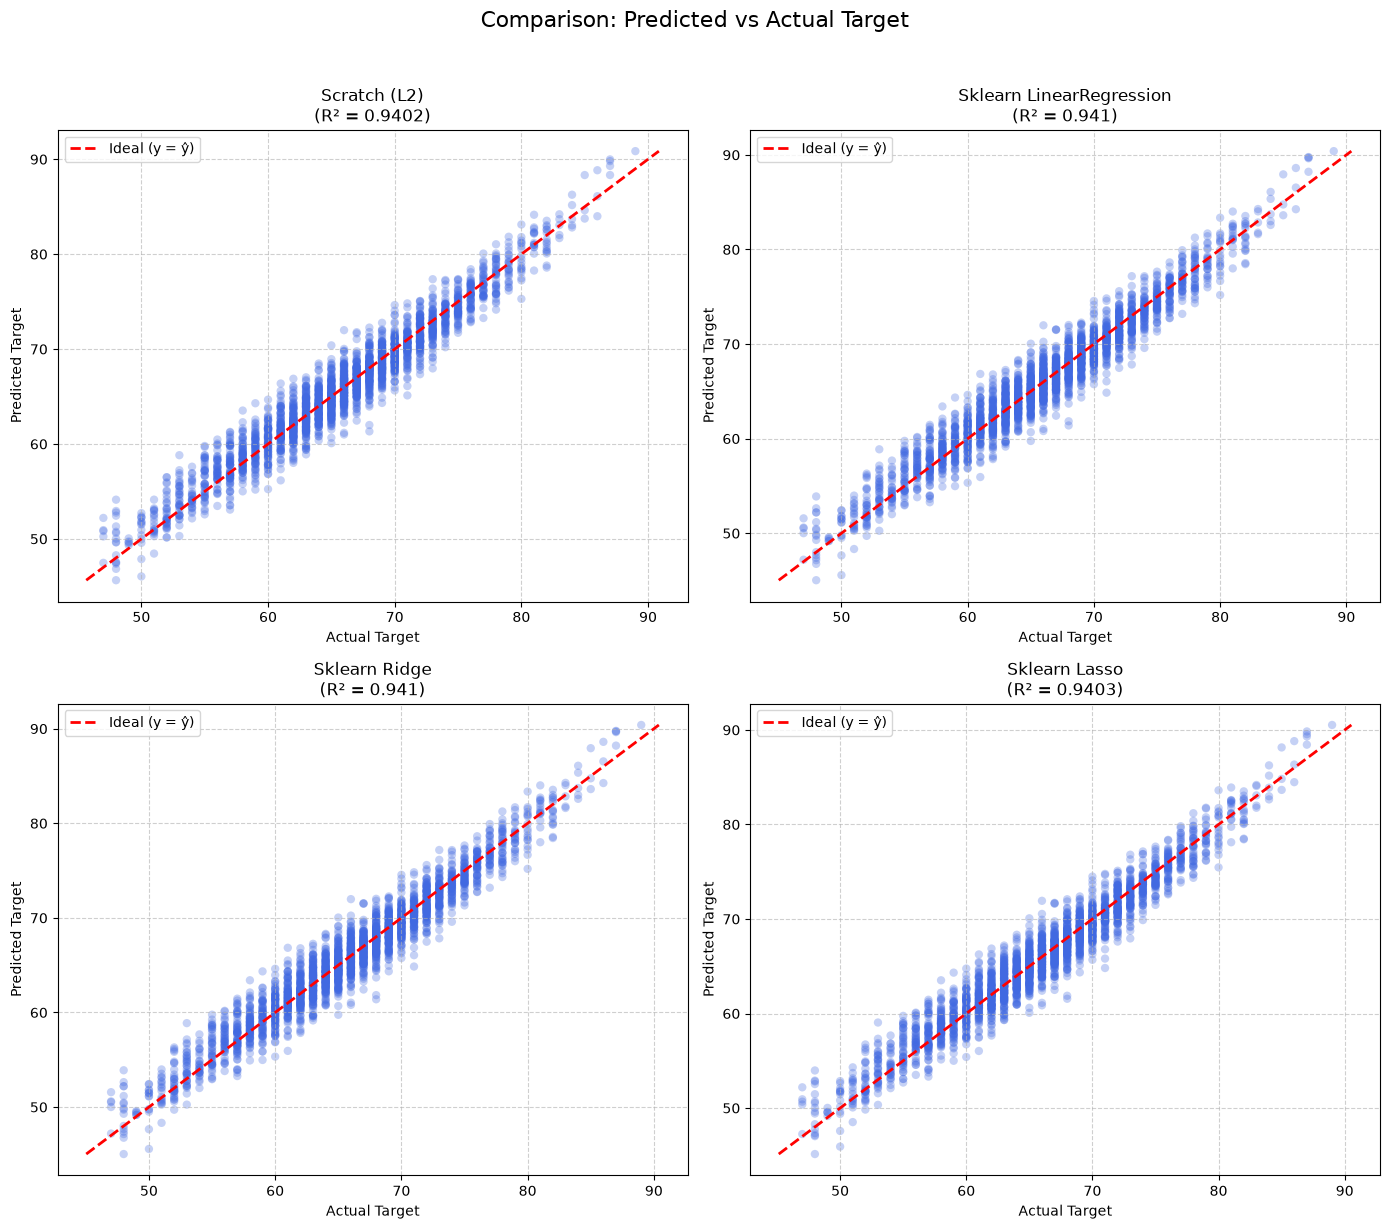

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(predictions.items()):
    ax = axes[i]
    ax.scatter(y_test, y_pred, alpha=0.3, color='royalblue', edgecolors='none')
    # Garis ideal 1:1
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal (y = ŷ)')
    ax.set_title(f'{name}\n(R² = {df_metrics.loc[df_metrics["Model"] == name, "R² Score"].values[0]})')
    ax.set_xlabel('Actual Target')
    ax.set_ylabel('Predicted Target')
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()

plt.suptitle('Comparison: Predicted vs Actual Target', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## 6. Visualisasi 2: Residual Plot

Residual didefinisikan sebagai $\text{Residual} = y - \hat{y}$ (selisih nilai aktual dan prediksi).
- Model yang baik memiliki residual yang tersebar **acak (homoscedasticity)** di sekitar garis horizontal $0$.
- Tidak ada pola melengkung atau menyempit/melebar.

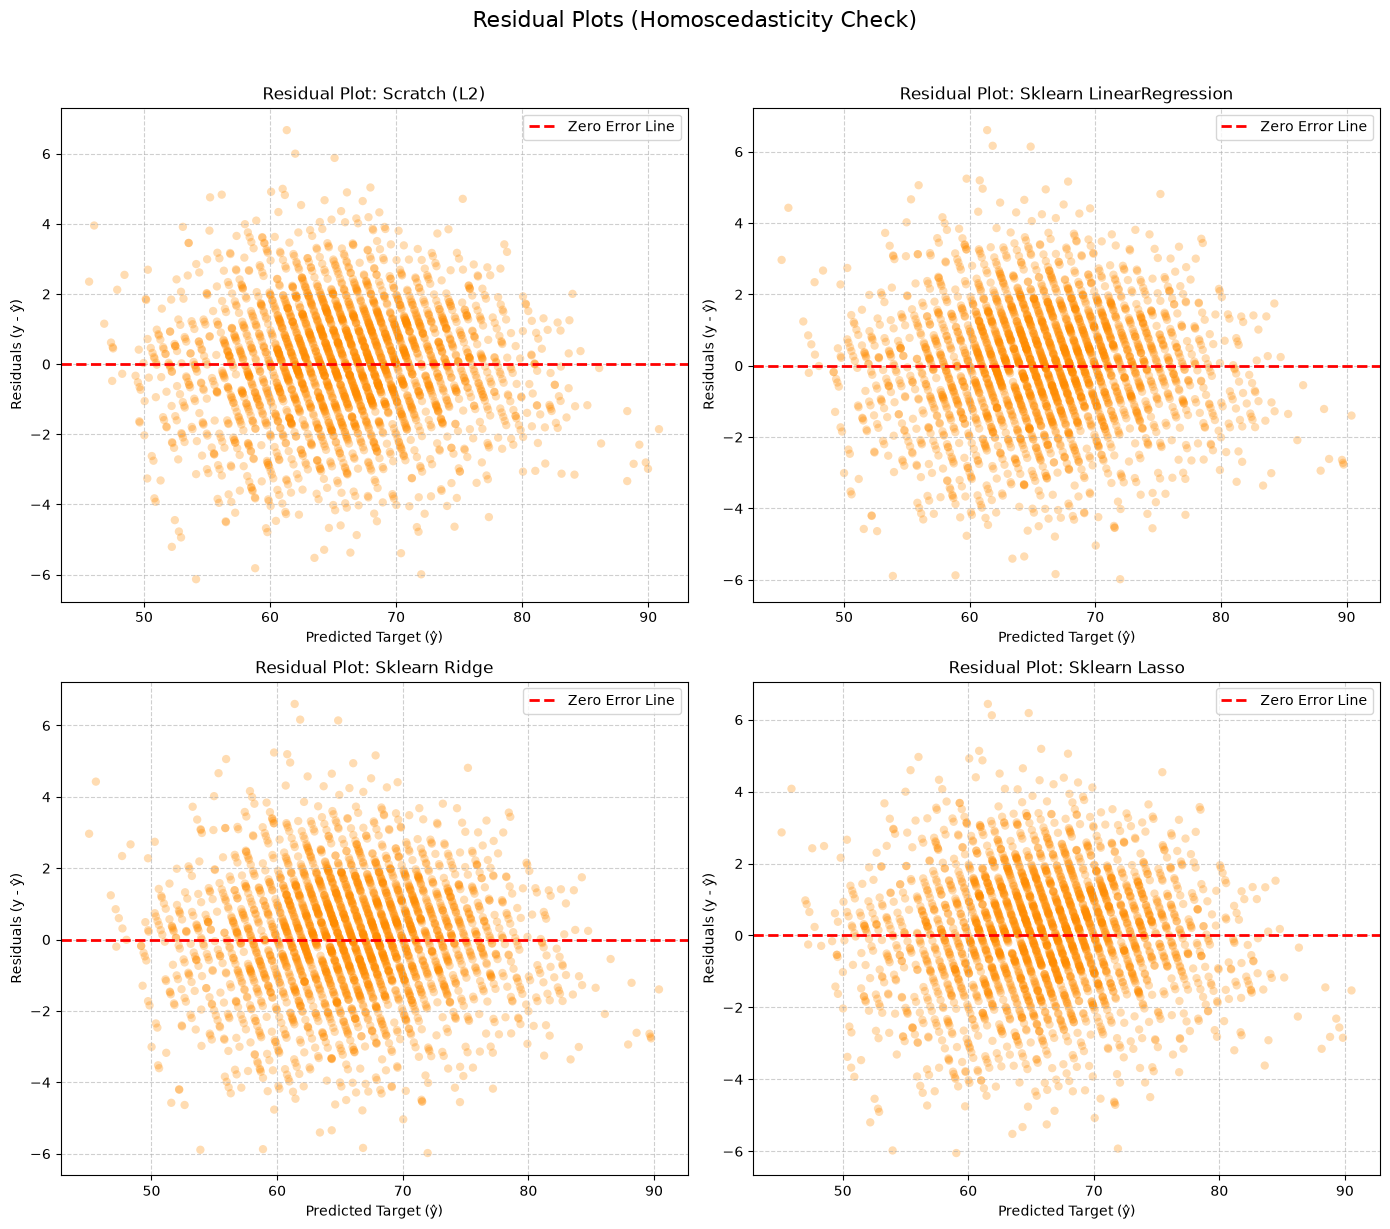

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(predictions.items()):
    ax = axes[i]
    residuals = y_test - y_pred
    ax.scatter(y_pred, residuals, alpha=0.3, color='darkorange', edgecolors='none')
    ax.axhline(0, color='red', linestyle='--', lw=2, label='Zero Error Line')
    ax.set_title(f'Residual Plot: {name}')
    ax.set_xlabel('Predicted Target (ŷ)')
    ax.set_ylabel('Residuals (y - ŷ)')
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()

plt.suptitle('Residual Plots (Homoscedasticity Check)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## 7. Visualisasi 3: Distribusi Residual (Histogram / KDE)

Salah satu asumsi regresi linear adalah residual berdistribusi normal di sekitar angka nol.

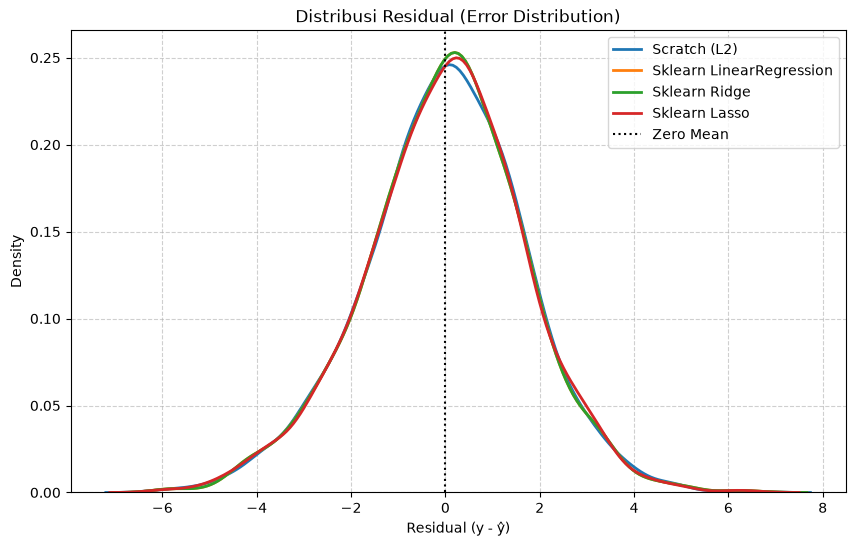

In [23]:
plt.figure(figsize=(10, 6))
for name, y_pred in predictions.items():
    residuals = y_test - y_pred
    sns.kdeplot(residuals, label=name, lw=2)

plt.axvline(0, color='black', linestyle=':', label='Zero Mean')
plt.title('Distribusi Residual (Error Distribution)')
plt.xlabel('Residual (y - ŷ)')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()